In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from eval import cal_ks_wd, cal_lambda

KS: 0.0220
WD: 0.0750


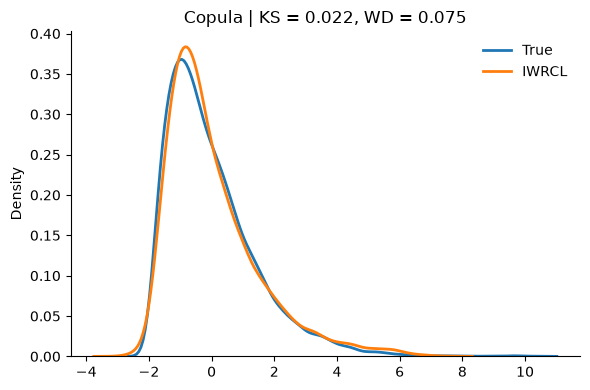

In [20]:
# Load data
df = pd.read_csv('../data/copula.csv', index_col=0)
u = df[['u.1', 'u.2', 'u.3', 'u.4', 'u.5']].values[:, 0]
generated = np.load("../save/copula/IWRCL/M100/seed42/generated.npy")[:, 0]

# Evaluation
ks, wd = cal_ks_wd(generated, u, "copula")
print(f"KS: {ks:.4f}")
print(f"WD: {wd:.4f}")

# Plot
plt.figure(figsize=(6, 4))

sns.kdeplot(u, label="True", linewidth=2)
sns.kdeplot(generated, label="IWRCL", linewidth=2)

plt.ylabel("Density")
plt.title(f"Copula | KS = {ks:.3f}, WD = {wd:.3f}")
plt.legend(frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

L1: 0.0350


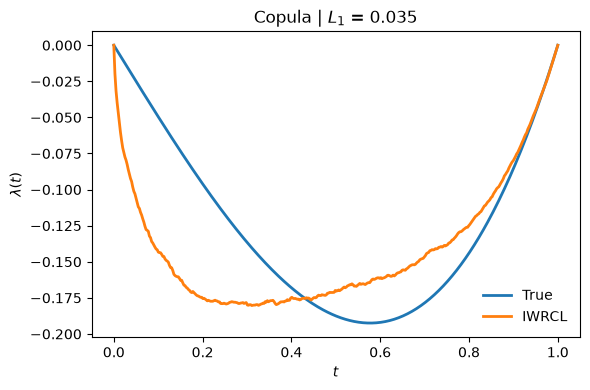

In [21]:
# True dependence function
points = np.linspace(0, 1, 400)
true = -0.5 * (points - points**3)

# IWRCL estimate
generated = np.load("../save/copula/IWRCL/M100/seed42/generated.npy")
estimated, l1, _ = cal_lambda(generated)

print(f"L1: {l1:.4f}")

# Plot
plt.figure(figsize=(6, 4))

plt.plot(points, true, label="True", linewidth=2)
plt.plot(points, estimated, label="IWRCL", linewidth=2)

plt.title(rf"Copula | $L_1$ = {l1:.3f}")
plt.xlabel(r"$t$")
plt.ylabel(r"$\lambda(t)$")
plt.legend(frameon=False)

plt.tight_layout()
plt.show()